# ein cnn für straßenobjekte

alle 50 bilder enthalten autos, lkw, fahrräder und personen. das cnn lernt daher für jedes objekt **klasse und position**. wir trainieren ssdlite mit mobilenetv3 mit zufälligen startgewichten auf der cpu.

## bilder aufteilen

40 bilder dienen zum lernen, 10 zur validierung. jede szene bleibt mit allen boxen in genau einer gruppe. die boxen im export sind relativ zur bildgröße angegeben; der detektor braucht ihre ecken in pixeln.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image
from torch.utils.data import DataLoader
from torchmetrics.detection import MeanAveragePrecision
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from torchvision.ops import box_convert, clip_boxes_to_image
from torchvision.transforms.functional import to_tensor

seed = 42
data = Path("data/coco-2017-yolo-50")
names = yaml.safe_load((data / "dataset.yaml").read_text())["names"]
ids = sorted((data.parent / "coco-2017-train-50.txt").read_text().splitlines())
assert len(ids) == len(set(ids)) == 50
random.Random(seed).shuffle(ids)
train_ids, val_ids = ids[:40], ids[40:]

In [2]:
def load_scene(image_id):
    with Image.open(data / "images/train" / f"{image_id}.jpg") as photo:
        image = to_tensor(photo.convert("RGB"))
    height, width = image.shape[-2:]
    label_path = data / "labels/train" / f"{image_id}.txt"
    rows = torch.from_numpy(np.loadtxt(label_path, dtype="float32").reshape(-1, 5))
    boxes = box_convert(rows[:, 1:], in_fmt="cxcywh", out_fmt="xyxy")
    boxes *= torch.tensor([width, height, width, height])
    target = {
        "boxes": clip_boxes_to_image(boxes, (height, width)),
        "labels": rows[:, 0].long() + 1,  # 0 ist für den hintergrund reserviert
    }
    return image, target

train = [load_scene(i) for i in train_ids]
valid = [load_scene(i) for i in val_ids]
for split, scenes in [("training", train), ("validierung", valid)]:
    boxes = sum(len(target["boxes"]) for _, target in scenes)
    print(f"{split}: {len(scenes)} bilder · {boxes} boxen")

training: 40 bilder · 593 boxen
validierung: 10 bilder · 146 boxen


## woran messen wir erfolg?

bei **map50** zählt eine vorhersage als treffer, wenn klasse und box passen. dafür muss die schnittfläche beider boxen mindestens die hälfte ihrer vereinigungsfläche betragen. pro klasse bewertet average precision die nach konfidenz sortierten treffer und fehlalarme über verschiedene recall-werte. alle vier klassen zählen gleich stark. wir messen einmal vor und einmal nach dem training. [metrik](https://lightning.ai/docs/torchmetrics/stable/detection/mean_average_precision.html)

In [3]:
@torch.inference_mode()
def evaluate(detector):
    detector.eval()
    metric = MeanAveragePrecision(iou_thresholds=[0.5], class_metrics=True)
    for image, target in valid:
        metric.update(detector([image]), [target])
    scores = metric.compute()
    by_class = {
        names[label - 1]: ap
        for label, ap in zip(scores["classes"].tolist(), scores["map_per_class"].tolist())
    }
    return pd.Series({**by_class, "map50": scores["map_50"].item()})

torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
model = ssdlite320_mobilenet_v3_large(
    weights=None, weights_backbone=None, num_classes=len(names) + 1, detections_per_img=100,
)
before = evaluate(model)

## trainieren

das cnn sieht jedes trainingsbild einmal pro epoche. es lernt gleichzeitig die objektklassen und die boxkoordinaten. wir legen vorab 30 epochen fest und bewerten den letzten modellstand.

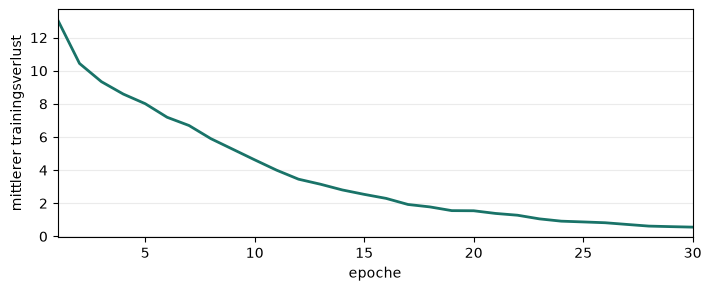

In [4]:
batches = DataLoader(train, batch_size=8, shuffle=True, collate_fn=list,
                     generator=torch.Generator().manual_seed(seed))
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
history = []
model.train()
for epoch in range(1, 31):
    epoch_loss = 0.0
    for batch in batches:
        images, targets = zip(*batch)
        optimizer.zero_grad(set_to_none=True)
        losses = model(list(images), list(targets))
        loss = sum(losses.values())
        if not loss.isfinite():
            raise ValueError(f"ungültiger verlust in epoche {epoch}")
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch)
    history.append(epoch_loss / len(train))

fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.plot(range(1, len(history) + 1), history, color="#197368", linewidth=2)
ax.set(xlabel="epoche", ylabel="mittlerer trainingsverlust", xlim=(1, len(history)))
ax.grid(axis="y", alpha=0.25)
plt.show()

## auswertung

die tabelle zeigt ap50 je klasse und den mittelwert auf denselben zehn validierungsbildern. die werte liegen zwischen 0 und 1; höher ist besser.

In [5]:
after = evaluate(model)
display(pd.DataFrame({"vor training": before, "nach training": after}).round(4))

checkpoint = Path("runs/cnn/ssdlite320.pt")
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save({
    "model": model.state_dict(),
    "class_names": {i + 1: name for i, name in names.items()},
    "train_ids": train_ids,
    "val_ids": val_ids,
}, checkpoint)
print(f"gewichte: {checkpoint}")

,vor training,nach training
car,0.0,0.0013
truck,0.0,0.0108
bicycle,0.0,0.0003
person,0.0,0.0121
map50,0.0,0.0061


gewichte: runs/cnn/ssdlite320.pt


## takeaway

der trainingsverlust sinkt deutlich. auf den zehn zurückgehaltenen bildern erreicht das cnn nach 30 epochen eine map50 von 0,0061 auf einer skala bis 1. das modell erkennt und lokalisiert die vier klassen auf diesen szenen noch unzuverlässig.